<a href="https://colab.research.google.com/github/saadkhokar-creator/231A019-NLP-Experiments/blob/main/aihhonors%20mini%20project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape: (768, 9)

Missing Values
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome               

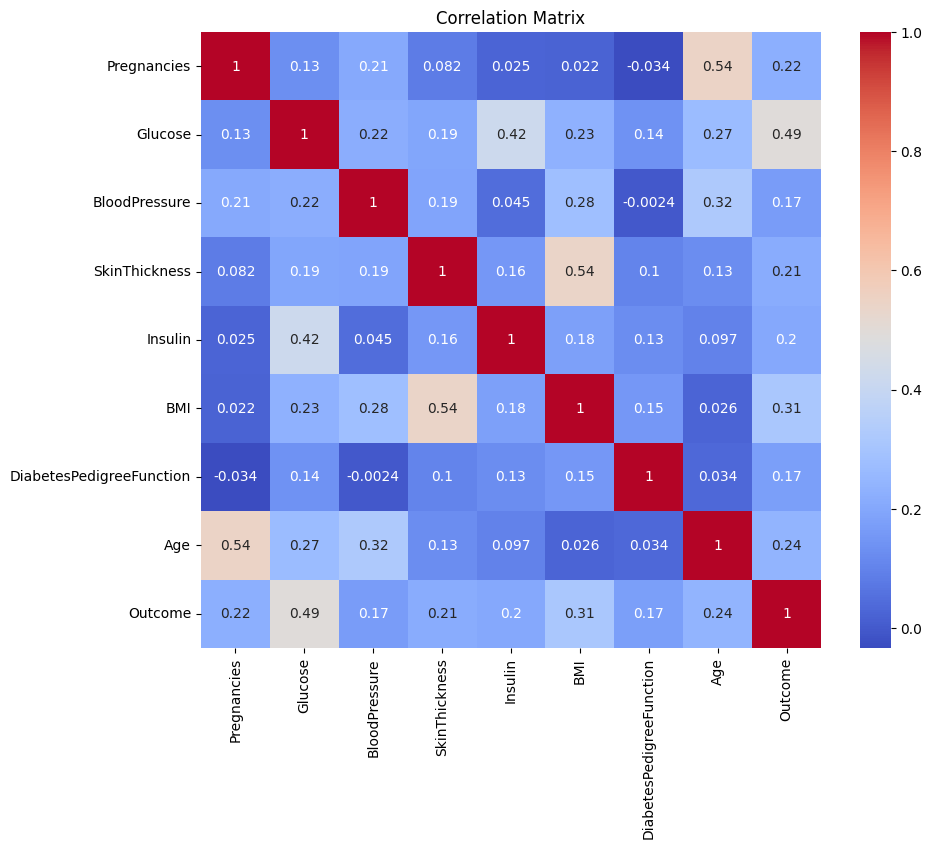


Logistic Regression
Accuracy: 0.7078
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


Decision Tree
Accuracy: 0.6818
              precision    recall  f1-score   support

           0       0.74      0.79      0.76       100
           1       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67      0.68      0.68       154


Random Forest
Accuracy: 0.7792
              precision    recall  f1-score   support

           0       0.80      0.88      0.84       100
           1       0.73      0.59      0.65        54

    accuracy                           0.78       154
   macro avg       0.76   

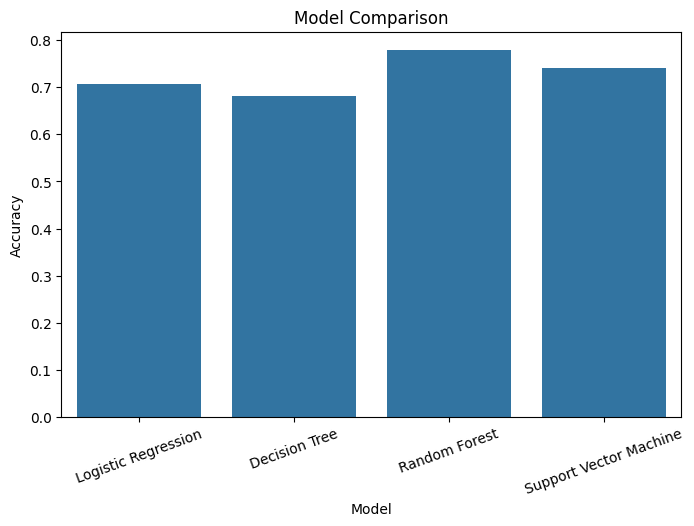

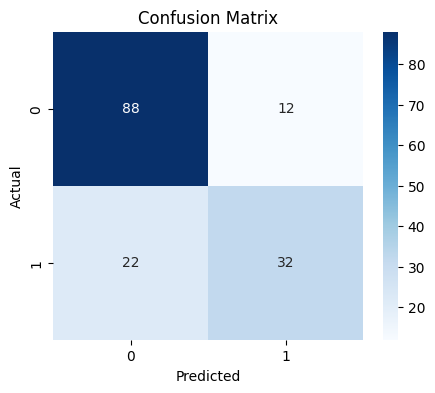

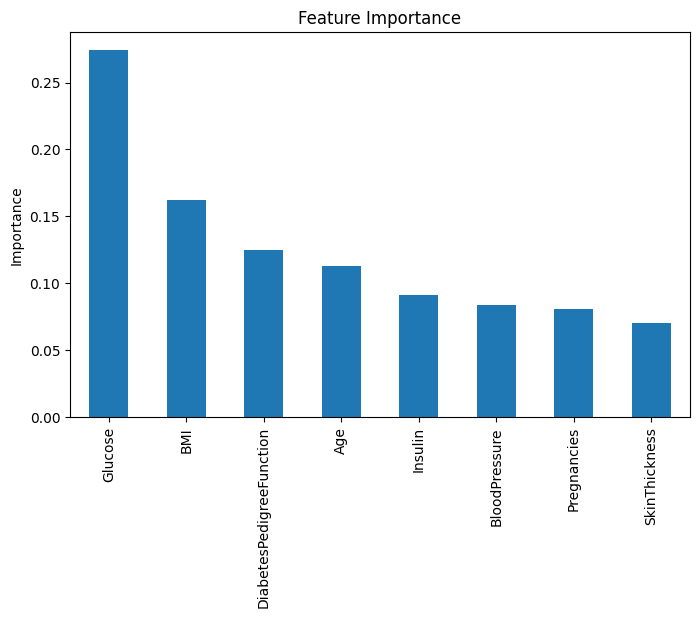


Feature Importance
Glucose                     0.274086
BMI                         0.161903
DiabetesPedigreeFunction    0.125020
Age                         0.112985
Insulin                     0.091224
BloodPressure               0.083518
Pregnancies                 0.080795
SkinThickness               0.070468
dtype: float64

Model Saved Successfully


In [1]:
# ===============================================
# Diabetes Prediction using Machine Learning
# ===============================================

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import joblib

# ===============================================
# Load Dataset
# ===============================================

df = pd.read_csv("diabetes.csv")

print(df.head())

print("\nDataset Shape:", df.shape)

print("\nMissing Values")
print(df.isnull().sum())

# ===============================================
# Replace Invalid Zeros with NaN
# ===============================================

cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[cols] = df[cols].replace(0, np.nan)

# ===============================================
# Fill Missing Values
# ===============================================

imputer = SimpleImputer(strategy="median")

df[cols] = imputer.fit_transform(df[cols])

# ===============================================
# Exploratory Data Analysis
# ===============================================

print(df.describe())

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# ===============================================
# Split Features and Target
# ===============================================

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# ===============================================
# Train Test Split
# ===============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ===============================================
# Feature Scaling
# ===============================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ===============================================
# Models
# ===============================================

models = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "Decision Tree":
        DecisionTreeClassifier(random_state=42),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),

    "Support Vector Machine":
        SVC()
}

results = {}

# ===============================================
# Training
# ===============================================

for name, model in models.items():

    if name in [
        "Logistic Regression",
        "Support Vector Machine"
    ]:

        model.fit(X_train_scaled, y_train)

        pred = model.predict(X_test_scaled)

    else:

        model.fit(X_train, y_train)

        pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)

    results[name] = acc

    print("\n==============================")
    print(name)
    print("==============================")

    print("Accuracy:", round(acc,4))

    print(classification_report(y_test, pred))

# ===============================================
# Model Comparison
# ===============================================

result_df = pd.DataFrame(
    results.items(),
    columns=["Model","Accuracy"]
)

print(result_df)

plt.figure(figsize=(8,5))

sns.barplot(
    data=result_df,
    x="Model",
    y="Accuracy"
)

plt.xticks(rotation=20)

plt.title("Model Comparison")

plt.show()

# ===============================================
# Best Model
# ===============================================

best_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

best_model.fit(X_train, y_train)

pred = best_model.predict(X_test)

# ===============================================
# Confusion Matrix
# ===============================================

cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

# ===============================================
# Feature Importance
# ===============================================

importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(ascending=False)

plt.figure(figsize=(8,5))

importance.plot(kind="bar")

plt.title("Feature Importance")

plt.ylabel("Importance")

plt.show()

print("\nFeature Importance")
print(importance)

# ===============================================
# Save Model
# ===============================================

joblib.dump(best_model, "diabetes_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("\nModel Saved Successfully")